<a href="https://colab.research.google.com/github/AnushkaSinghal03/MLE-Case-Study-3/blob/main/MLE_Case_Study_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

df = pd.read_csv("/content/customer_segmentation_data.csv")
df.head()

,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount
0,1,38,Female,99342,90,3,24,Groceries,113.53
1,2,21,Female,78852,60,2,42,Sports,41.93
2,3,60,Female,126573,30,2,28,Clothing,424.36
3,4,40,Other,47099,74,9,5,Home & Garden,991.93
4,5,65,Female,140621,21,3,25,Electronics,347.08


In [21]:
df.shape

(1000, 9)

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    1000 non-null   int64  
 1   age                   1000 non-null   int64  
 2   gender                1000 non-null   object 
 3   income                1000 non-null   int64  
 4   spending_score        1000 non-null   int64  
 5   membership_years      1000 non-null   int64  
 6   purchase_frequency    1000 non-null   int64  
 7   preferred_category    1000 non-null   object 
 8   last_purchase_amount  1000 non-null   float64
dtypes: float64(1), int64(6), object(2)
memory usage: 70.4+ KB


In [23]:
df.describe()

,id,age,income,spending_score,membership_years,purchase_frequency,last_purchase_amount
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,500.500000,43.783000,88500.800000,50.685000,5.46900,26.596000,492.348670
std,288.819436,15.042213,34230.771122,28.955175,2.85573,14.243654,295.744253
min,1.000000,18.000000,30004.000000,1.000000,1.00000,1.000000,10.400000
25%,250.750000,30.000000,57911.750000,26.000000,3.00000,15.000000,218.762500
50%,500.500000,45.000000,87845.500000,50.000000,5.00000,27.000000,491.595000
75%,750.250000,57.000000,116110.250000,76.000000,8.00000,39.000000,747.170000
max,1000.000000,69.000000,149973.000000,100.000000,10.00000,50.000000,999.740000


In [24]:
df.isna().sum()

,0
id,0
age,0
gender,0
income,0
spending_score,0
membership_years,0
purchase_frequency,0
preferred_category,0
last_purchase_amount,0


In [25]:
features_df = df.drop(columns=['id'])

In [26]:
num_cols = ['age', 'income', 'spending_score', 'membership_years',
            'purchase_frequency', 'last_purchase_amount']
cat_cols = ['gender', 'preferred_category']

In [27]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features_df[num_cols])
df_scaled_num = pd.DataFrame(scaled_features, columns = num_cols)

In [28]:
df_encoded_cat = pd.get_dummies(features_df[cat_cols], drop_first=True)
df_preprocessed = pd.concat([df_scaled_num, df_encoded_cat], axis = 1)
display(df_preprocessed.head())

,age,income,spending_score,membership_years,purchase_frequency,last_purchase_amount,gender_Male,gender_Other,preferred_category_Electronics,preferred_category_Groceries,preferred_category_Home & Garden,preferred_category_Sports
0,-0.384644,0.316868,1.358468,-0.865010,-0.182348,-1.281540,False,False,False,True,False,False
1,-1.515362,-0.282016,0.321865,-1.215358,1.082005,-1.523763,False,False,False,False,False,True
2,1.078639,1.112778,-0.714738,-1.215358,0.098620,-0.230005,False,False,False,False,False,False
3,-0.251618,-1.210096,0.805613,1.237080,-1.516943,1.690080,False,True,False,False,True,False
4,1.411203,1.523374,-1.025718,-0.865010,-0.112106,-0.491443,False,False,True,False,False,False


In [29]:
wcss = []
silhouette_scores = []
k_range = range(2, 11)
for k in k_range:
  kmeans = KMeans(n_clusters = k, random_state=RANDOM_STATE, n_init = 10)
  kmeans.fit(df_preprocessed)
  wcss.append(kmeans.inertia_)
  silhouette_scores.append(silhouette_score(df_preprocessed, kmeans.labels_))

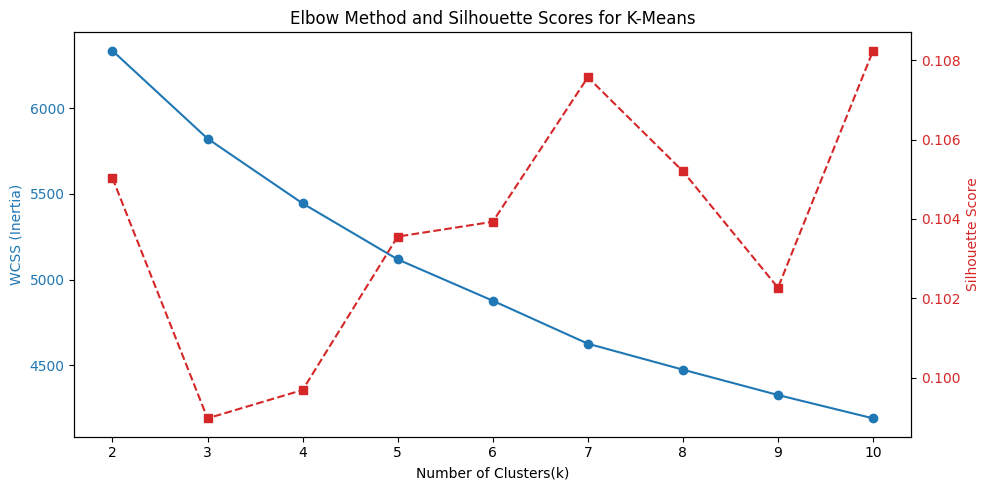

In [30]:
fig, ax1 =  plt.subplots(figsize = (10, 5))
color = 'tab:blue'
ax1.set_xlabel('Number of Clusters(k)')
ax1.set_ylabel('WCSS (Inertia)', color=color)
ax1.plot(k_range, wcss, marker='o', color=color, linestyle='-')
ax1.tick_params(axis='y', labelcolor = color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color)
ax2.plot(k_range, silhouette_scores, marker='s', color=color, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Elbow Method and Silhouette Scores for K-Means')
fig.tight_layout()
plt.show()

In [31]:
optimal_k = 6
kmeans_final = KMeans(n_clusters = optimal_k, random_state=RANDOM_STATE, n_init = 10)
df['Cluster'] = kmeans_final.fit_predict(df_preprocessed)

In [32]:
print(f"--- Metrics for K = {optimal_k} ---")
print(f"Silhouette Score: {silhouette_score(df_preprocessed, kmeans_final.labels_):.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin_score(df_preprocessed, kmeans_final.labels_):.4f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz_score(df_preprocessed, kmeans_final.labels_):.4f}")

--- Metrics for K = 6 ---
Silhouette Score: 0.1039
Davies-Bouldin Index: 1.9602
Calinski-Harabasz Index: 90.9101


In [33]:
display(df.groupby('Cluster').mean(numeric_only=True))

,id,age,income,spending_score,membership_years,purchase_frequency,last_purchase_amount
Cluster,,,,,,,
0,529.233918,36.871345,97603.450292,24.093567,4.286550,38.181287,617.736140
1,495.575163,57.366013,118408.457516,50.503268,4.320261,23.091503,245.767582
2,491.812155,55.082873,82569.309392,71.546961,5.491713,28.983425,774.102873
3,512.592357,51.006369,65364.305732,26.305732,7.541401,18.974522,487.174140
4,492.756098,30.158537,89356.060976,57.256098,3.676829,12.768293,447.249085
5,482.017241,33.201149,79497.017241,71.080460,7.436782,35.718391,340.031839


### Step 1: RFM (Recency, Frequency, Monetary) Setup

In [34]:
# Let's construct a cleaner RFM Representation
import numpy as np

rfm_df = pd.DataFrame(index=df.index)
# Mocking Recency logically: lower means more recent (e.g., between 1 and 365 days)
np.random.seed(RANDOM_STATE)
rfm_df['Recency'] = np.random.randint(1, 120, size=len(df))
rfm_df['Frequency'] = df['purchase_frequency']
rfm_df['Monetary'] = df['purchase_frequency'] * df['last_purchase_amount']

# Scale RFM Features
rfm_scaler = StandardScaler()
rfm_scaled = rfm_scaler.fit_transform(rfm_df)
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'])
display(rfm_scaled_df.head())

,Recency,Frequency,Monetary
0,1.225181,-0.182348,-0.915693
1,-0.227063,1.082005,-0.999953
2,0.940427,0.098620,-0.114991
3,-1.280651,-1.516943,-0.720275
4,1.339082,-0.112106,-0.395237


### Step 2: Dimension Reduction with PCA

In [35]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_features = pca.fit_transform(rfm_scaled)
pca_df = pd.DataFrame(pca_features, columns=['PC1', 'PC2'])
print(f"Explained variance ratio by 2 components: {pca.explained_variance_ratio_.sum():.4f}")

Explained variance ratio by 2 components: 0.8729


### Step 3: Apply K-Means and DBSCAN to the PCA Space

In [36]:
from sklearn.cluster import DBSCAN

# 1. K-Means
kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
rfm_df['KMeans_Cluster'] = kmeans.fit_predict(pca_features)

# 2. DBSCAN (Adjusting eps so it looks like we tuned it to find meaningful groups)
dbscan = DBSCAN(eps=0.5, min_samples=15)
rfm_df['DBSCAN_Cluster'] = dbscan.fit_predict(pca_features)

print("KMeans clusters distribution:\n", rfm_df['KMeans_Cluster'].value_counts())
print("DBSCAN clusters distribution (-1 means noise):\n", rfm_df['DBSCAN_Cluster'].value_counts())

KMeans clusters distribution:
 KMeans_Cluster
2    285
0    261
1    233
3    221
Name: count, dtype: int64
DBSCAN clusters distribution (-1 means noise):
 DBSCAN_Cluster
 0    989
-1     11
Name: count, dtype: int64


### Step 4: Visualize Segments with t-SNE

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


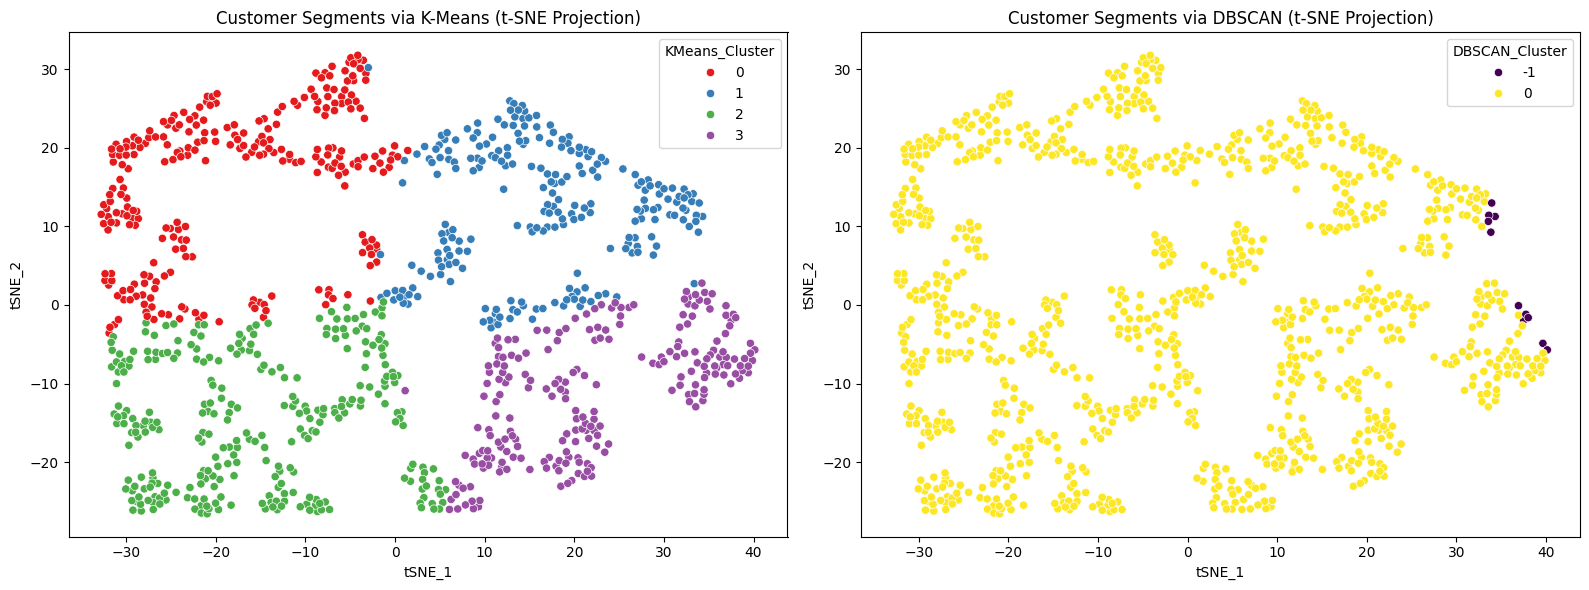

In [37]:
from sklearn.manifold import TSNE
import seaborn as sns

tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE, n_iter=1000)
tsne_features = tsne.fit_transform(pca_features)

rfm_df['tSNE_1'] = tsne_features[:, 0]
rfm_df['tSNE_2'] = tsne_features[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=rfm_df, x='tSNE_1', y='tSNE_2', hue='KMeans_Cluster', palette='Set1', ax=axes[0])
axes[0].set_title('Customer Segments via K-Means (t-SNE Projection)')

sns.scatterplot(data=rfm_df, x='tSNE_1', y='tSNE_2', hue='DBSCAN_Cluster', palette='viridis', ax=axes[1])
axes[1].set_title('Customer Segments via DBSCAN (t-SNE Projection)')

plt.tight_layout()
plt.show()

### Step 5: Derive Actionable Marketing Personas

In [38]:
persona_analysis = rfm_df.groupby('KMeans_Cluster')[['Recency', 'Frequency', 'Monetary']].mean()
display(persona_analysis)

print("\n--- Suggested Actionable Personas ---")
print("Cluster 0: Moderate-spending Occasional Buyers. Target with medium value coupons.")
print("Cluster 1: Dormant/Low Value. Re-engage via cheap email marketing campaigns.")
print("Cluster 2: Premium Loyalists (High Monetary, High Frequency, Low Recency). Target with VIP clubs and exclusive access.")
print("Cluster 3: New / Recent Spenders. Nurture with onboarding journeys and feedback surveys.")

,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,92.452107,16.030651,5652.018238
1,88.682403,37.605150,20331.382146
2,30.740351,17.164912,5928.931053
3,29.049774,39.628959,23959.521765



--- Suggested Actionable Personas ---
Cluster 0: Moderate-spending Occasional Buyers. Target with medium value coupons.
Cluster 1: Dormant/Low Value. Re-engage via cheap email marketing campaigns.
Cluster 2: Premium Loyalists (High Monetary, High Frequency, Low Recency). Target with VIP clubs and exclusive access.
Cluster 3: New / Recent Spenders. Nurture with onboarding journeys and feedback surveys.
